# 逆行列を明示的に計算してはいけない理由

## 概要

正則な行列の方程式 $\mathbf{A}\mathbf{x}=\mathbf{b}$ は、$\mathbf{x}=\mathbf{A}^{-1}\mathbf{b}$ と解ける。逆行列を作る場合と直接解く場合の計算量、誤差、保存量を比較する。

## 実行環境

環境は `wa-src(3.14.6)` である。小数は表示時だけ有効数字3桁に丸める。図はSVGで表示し、`104_nb_files` に保存する。

In [1]:
import sys
from pathlib import Path
from pprint import pprint
from timeit import repeat

import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
import scipy
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.linalg import hilbert, lu_factor, lu_solve
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

%matplotlib inline

assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix
print(f"実行環境: wa-src({sys.version.split()[0]})")
print(f"NumPy {np.__version__}, SciPy {scipy.__version__}")
print(f"Matplotlib {matplotlib.__version__}, mpmath {mp.__version__}")
np.set_printoptions(formatter={"float_kind": lambda v: f"{v:.2e}"})
set_matplotlib_formats("svg")
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True,
                     "grid.alpha": 0.250, "svg.fonttype": "none"})
figure_dir = Path("104_nb_files")
figure_dir.mkdir(exist_ok=True)
rng = np.random.default_rng(104)


def save_figure(fig, name):
    """目盛りを整え、SVGで保存・表示する。"""
    fmt = FuncFormatter(lambda v, _: str(int(v)) if v == int(v) else f"{v:#.3g}")
    for ax in fig.axes:
        if ax.get_xscale() == "linear":
            ax.xaxis.set_major_formatter(fmt)
        if ax.get_yscale() == "linear" and ax.yaxis.units is None:
            ax.yaxis.set_major_formatter(fmt)
    fig.savefig(figure_dir / name, format="svg", bbox_inches="tight")
    plt.show()


def seconds(func):
    """予備実行後、3回×5組の1回あたりの中央値を返す。"""
    func()
    return float(np.median(repeat(func, number=3, repeat=5))) / 3

実行環境: wa-src(3.14.6)
NumPy 2.5.4, SciPy 1.18.1
Matplotlib 3.11.2, mpmath 1.3.0


## 1. 解の式と計算手順は別である

<div>
$$
\mathbf{A}=\begin{bmatrix}2&1\\1&1\end{bmatrix},\quad
\mathbf{b}=\begin{bmatrix}3\\2\end{bmatrix},\quad
\mathbf{A}\mathbf{x}=\mathbf{b}.
$$
</div>

行列式は $2\times1-1\times1=1$ であり、

<div>
$$
\mathbf{A}^{-1}=\frac{1}{2\times1-1\times1}
\begin{bmatrix}1&-1\\-1&2\end{bmatrix},\qquad
\mathbf{x}=\begin{bmatrix}1\times3-1\times2\\-1\times3+2\times2\end{bmatrix}
=\begin{bmatrix}1\\1\end{bmatrix}.
$$
</div>

下三角行列と上三角行列に分解すると、

<div>
$$
\mathbf{A}=\mathbf{L}\mathbf{U}
=\begin{bmatrix}1&0\\1/2&1\end{bmatrix}
\begin{bmatrix}2&1\\0&1/2\end{bmatrix}.
$$
</div>

$\mathbf{L}\mathbf{y}=\mathbf{b}$ を上から、$\mathbf{U}\mathbf{x}=\mathbf{y}$ を下から解く。

<div>
$$
\begin{aligned}
y_1&=3,& y_2&=2-\frac12y_1=2-\frac32=\frac12,\\
x_2&=\frac{y_2}{1/2}=1,& x_1&=\frac{y_1-x_2}{2}=\frac{3-1}{2}=1.
\end{aligned}
$$
</div>

一般には行の交換を表す $\mathbf{P}$ を用いて $\mathbf{P}\mathbf{A}=\mathbf{L}\mathbf{U}$ と分解し、$\mathbf{L}\mathbf{y}=\mathbf{P}\mathbf{b}$ を解く。[NumPyの `solve`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html) はLAPACKの `gesv` によって求解する。

In [2]:
A = np.array([[2, 1], [1, 1]], dtype=float)
b = np.array([3, 2], dtype=float)
pprint({"solve": np.linalg.solve(A, b), "inv @ b": np.linalg.inv(A) @ b})
display(Math(r"\mathbf{x}=\begin{bmatrix}1\\1\end{bmatrix}"))

{'inv @ b': array([1.00e+00, 1.00e+00]), 'solve': array([1.00e+00, 1.00e+00])}


<IPython.core.display.Math object>

## 2. 逆行列は必要以上の計算を行う

密な $n$ 次行列のLU分解では、残りの成分に乗算と減算を行う。除算などの低次項を除いた回数は、

<div>
$$
F(n)\simeq2\sum_{m=1}^{n-1}m^2
=\frac{(n-1)n(2n-1)}{3}
\simeq\frac23n^3.
$$
</div>

三角系1個では約 $2\sum_{i=1}^{n}(i-1)=n(n-1)$ 回、2個で約 $2n^2$ 回である。

逆行列の第 $j$ 列を $\mathbf{c}_j$ とすると、$\mathbf{A}\mathbf{c}_j=\mathbf{e}_j$ である。$\mathbf{e}_j$ は第 $j$ 成分だけが1のベクトルである。全列を三角求解で求める見積もりは、

<div>
$$
\begin{aligned}
\text{直接求解}&:\quad F(n)+2n^2,\\
\text{逆行列を経由}&:\quad F(n)+n\times2n^2+2n^2.
\end{aligned}
$$
</div>

最後の項は逆行列と右辺の積である。専用アルゴリズムでは係数が変わるので、`inv` の正確な演算回数ではない。どちらも $O(n^3)$ だが、逆行列には追加計算がある。

対角成分を大きくした行列で時間を測る。生成時間を除き、分解・逆行列計算を含める。BLASは既定の設定であり、時間比は環境による。

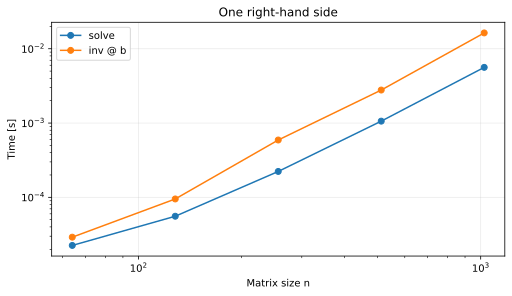

In [3]:
sizes = [64, 128, 256, 512, 1024]
times = {"solve": [], "inv @ b": []}
for n in sizes:
    A = rng.standard_normal((n, n)) + n * np.eye(n)
    b = rng.standard_normal(n)
    times["solve"].append(seconds(lambda: np.linalg.solve(A, b)))
    times["inv @ b"].append(seconds(lambda: np.linalg.inv(A) @ b))
fig, ax = plt.subplots(layout="constrained")
for name, values in times.items():
    ax.loglog(sizes, values, "o-", label=name)
ax.set(xlabel="Matrix size n", ylabel="Time [s]", title="One right-hand side")
ax.legend()
save_figure(fig, "01_solve_time.svg")

## 3. 丸め誤差と条件数を分けて考える

逆行列の計算誤差を $\mathbf{E}$、積の計算誤差を $\mathbf{d}$ と書くと、

<div>
$$
\begin{aligned}
\widehat{\mathbf{x}}&=(\mathbf{A}^{-1}+\mathbf{E})\mathbf{b}+\mathbf{d},\\
\widehat{\mathbf{x}}-\mathbf{x}&=\mathbf{E}\mathbf{b}+\mathbf{d},\\
\mathbf{r}=\mathbf{b}-\mathbf{A}\widehat{\mathbf{x}}
&=-\mathbf{A}\mathbf{E}\mathbf{b}-\mathbf{A}\mathbf{d}.
\end{aligned}
$$
</div>

逆行列と積の両方の誤差が残差に入る。大きな項が相殺されると相対誤差は大きくなり得る。ただし、逆行列で必ず精度が悪くなるわけではない。一定の仮定で直接求解と同程度の前進誤差になることも示されている。[Druinsky・Toledoの論文](https://arxiv.org/abs/1201.6035)

残差だけでも精度は判断できない。ここでは2ノルムを使う。$\mathbf{A}(\mathbf{x}-\widehat{\mathbf{x}})=\mathbf{r}$ より、

<div>
$$
\begin{aligned}
\|\mathbf{x}-\widehat{\mathbf{x}}\|_2
&=\|\mathbf{A}^{-1}\mathbf{r}\|_2
\le\|\mathbf{A}^{-1}\|_2\|\mathbf{r}\|_2,\\
\|\mathbf{b}\|_2&=\|\mathbf{A}\mathbf{x}\|_2
\le\|\mathbf{A}\|_2\|\mathbf{x}\|_2,\\
\frac{\|\mathbf{x}-\widehat{\mathbf{x}}\|_2}{\|\mathbf{x}\|_2}
&\le\|\mathbf{A}^{-1}\|_2\|\mathbf{A}\|_2
\frac{\|\mathbf{r}\|_2}{\|\mathbf{b}\|_2}
=\kappa_2(\mathbf{A})\rho.
\end{aligned}
$$
</div>

$\rho=\|\mathbf{r}\|_2/\|\mathbf{b}\|_2$ は相対残差である。条件数 $\kappa_2(\mathbf{A})$ が大きいと、`solve` でも前進誤差は大きくなり得る。不等式は上限を表す。

### Hilbert行列で確認する

成分が $h_{ij}=1/(i+j-1)$ の行列を使う。右辺 $\mathbf{H}\mathbf{1}$ を倍精度で作ると、丸めにより厳密解は $\mathbf{1}$ からずれ得る。そこで保存された入力を80桁精度へ移して参照解と残差を求める。

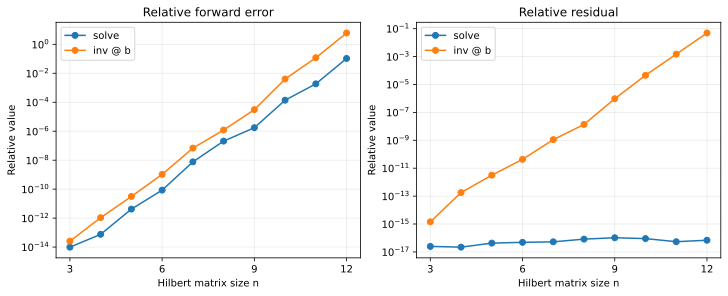

{'condition number (n=12)': '1.72e+16'}
{'inv @ b': {'forward error': '6.06e+00', 'relative residual': '4.87e-02'},
 'solve': {'forward error': '1.06e-01', 'relative residual': '6.88e-17'}}


In [4]:
orders = np.arange(3, 13)
errors = {name: [] for name in ("solve", "inv @ b")}
residuals = {name: [] for name in errors}
conditions = []
with mp.workdps(80):
    for n in orders:
        H = hilbert(int(n))
        b = H @ np.ones(n)
        # floatの値を直接渡し、短い小数文字列への丸めを避ける。
        H_mp, b_mp = mp.matrix(H.tolist()), mp.matrix(b.tolist())
        reference = mp.lu_solve(H_mp, b_mp)
        conditions.append(np.linalg.cond(H))
        for name, x in (("solve", np.linalg.solve(H, b)),
                        ("inv @ b", np.linalg.inv(H) @ b)):
            x_mp = mp.matrix(x.tolist())
            errors[name].append(float(mp.norm(x_mp - reference) / mp.norm(reference)))
            residuals[name].append(float(mp.norm(b_mp - H_mp * x_mp) / mp.norm(b_mp)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for name in errors:
    axes[0].semilogy(orders, errors[name], "o-", label=name)
    axes[1].semilogy(orders, residuals[name], "o-", label=name)
for ax, title in zip(axes, ["Relative forward error", "Relative residual"]):
    ax.set(xlabel="Hilbert matrix size n", ylabel="Relative value", title=title)
    ax.set_xticks([3, 6, 9, 12])
    ax.legend()
save_figure(fig, "02_error_and_residual.svg")
pprint({"condition number (n=12)": f"{conditions[-1]:.2e}"})
pprint({name: {"forward error": f"{errors[name][-1]:.2e}",
               "relative residual": f"{residuals[name][-1]:.2e}"} for name in errors})

この例では `inv @ b` の残差が大きくなる。`solve` も次数が大きいと解の誤差を抑えられない。私は残差と条件数を併せて確認するようにしている。ただし、条件数の計算自体も安価ではない。

## 4. 複数の右辺と分解の再利用

右辺を並べた $\mathbf{B}$ に対し、$\mathbf{A}\mathbf{X}=\mathbf{B}$ を解く。右辺が $k$ 本なら、LU分解の再利用で計算量は約 $F(n)+2kn^2$ となる。毎回分解する場合は $k\{F(n)+2n^2\}$ である。

[SciPyの `lu_solve`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.lu_solve.html) は `lu_factor` の結果を再利用する。行列が変わった場合は分解し直す。

{'relative residual (Frobenius)': '1.06e-15'}


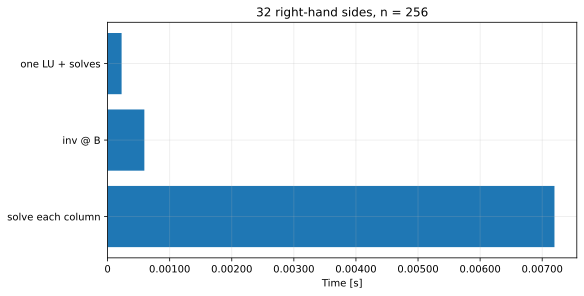

In [5]:
n, k = 256, 32
A = rng.standard_normal((n, n)) + n * np.eye(n)
B = rng.standard_normal((n, k))
factor = lu_factor(A)
X = lu_solve(factor, B)
pprint({"relative residual (Frobenius)": f"{np.linalg.norm(B - A @ X) / np.linalg.norm(B):.2e}"})

methods = {
    "solve each column": lambda: np.column_stack([np.linalg.solve(A, b) for b in B.T]),
    "inv @ B": lambda: np.linalg.inv(A) @ B,
    "one LU + solves": lambda: lu_solve(lu_factor(A), B),
}
batch_times = {name: seconds(func) for name, func in methods.items()}
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(list(batch_times), list(batch_times.values()))
ax.set(xlabel="Time [s]", title="32 right-hand sides, n = 256")
save_figure(fig, "03_multiple_rhs.svg")

## 5. 疎行列の逆行列は密になることがある

対角が2、両隣が $-1$ の三重対角行列は、非零成分が $n+2(n-1)=3n-2$ 個だが、逆行列は全成分が非零となる。小さな行列を密に変換し、非零の位置を点で示す。

{'relative residual': '1.59e-14'}


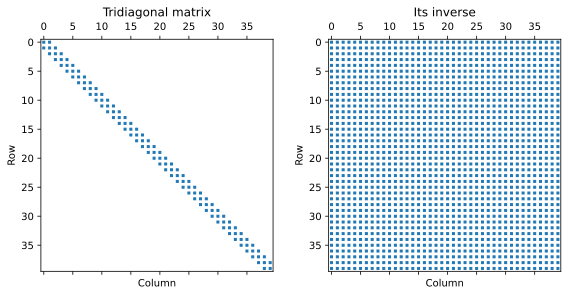

In [6]:
n = 40
S = diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)],
          offsets=[-1, 0, 1], format="csc")
C = np.linalg.inv(S.toarray())
b = np.ones(n)
x = spsolve(S, b)
pprint({"relative residual": f"{np.linalg.norm(b - S @ x) / np.linalg.norm(b):.2e}"})
fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, matrix, title in zip(axes, [S, C], ["Tridiagonal matrix", "Its inverse"]):
    ax.spy(matrix, markersize=2)
    ax.set(title=title, xlabel="Column", ylabel="Row")
    ax.grid(False)
save_figure(fig, "04_nonzero_pattern.svg")

倍精度の密行列は $8n^2$ バイトを要する。CSC形式は非零値、行番号、列の開始位置を保存し、この例では $O(n)$ となる。図は配列の容量だけを比較し、管理・作業領域を含めない。

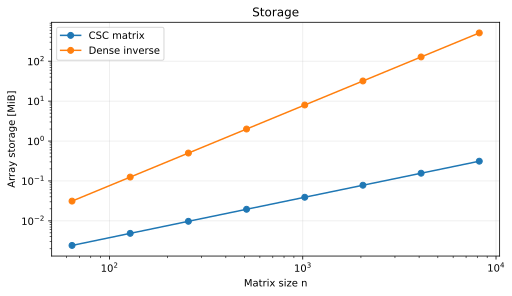

In [7]:
sizes = 2 ** np.arange(6, 14)
sparse_bytes = []
for n in sizes:
    S = diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)],
              offsets=[-1, 0, 1], format="csc")
    sparse_bytes.append(S.data.nbytes + S.indices.nbytes + S.indptr.nbytes)
# 逆行列は作らず、要素数から容量を求める。
dense_bytes = 8 * sizes ** 2
fig, ax = plt.subplots(layout="constrained")
ax.loglog(sizes, np.array(sparse_bytes) / 2 ** 20, "o-", label="CSC matrix")
ax.loglog(sizes, dense_bytes / 2 ** 20, "o-", label="Dense inverse")
ax.set(xlabel="Matrix size n", ylabel="Array storage [MiB]", title="Storage")
ax.legend()
save_figure(fig, "05_storage.svg")

疎な方程式には [SciPyの `spsolve`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.spsolve.html) などを使う。疎LU分解でも元は零の位置に非零値が生じるので、常に $O(n)$ のメモリで解けるわけではない。

## 結論

この記事では、逆行列を経由する求解の計算量、誤差、保存量を比較し、分解の再利用を示した。

求解には `solve`、同じ行列で右辺が変わる場合にはLU分解の再利用が基本である。悪条件の影響は残る。逆行列の全成分が必要な処理や記号計算は別として、解だけが必要な場面では作らない。